# 06 · Robustness: does the edge survive on Zillow's raw index?

Notebooks 02-05 forecast Zillow's **smoothed, seasonally adjusted** index, the series Zillow itself
forecasts. Smoothing makes it unusually easy to forecast a month or two ahead: this month's
smoothed value already contains part of next month's. So the clear 1-3 month gain over momentum
(notebook 05) could be partly an artefact of the smoothing.

This notebook rebuilds the same counties, housing-unit weights and hierarchy from the **raw**
index (neither smoothed nor seasonally adjusted), refits every model on it, and scores the forecasts
against raw outcomes. The raw index has a seasonal cycle, so one more simple rule joins the bar
to beat: **seasonal naive**, growth over the next h months = the same months' growth a year earlier.

| | |
|---|---|
| **Question** | Do the reconciled forecasts still beat the simple rules when the target is the raw index? |
| **Answer** | Partly. On the raw index the 1-month gain survives: metro error 32% below the best simple rule (95% interval 25% to 39%), down from 60% on the smoothed index. The 3-month gain does not: 10% below seasonal naive, with an interval from -5% to +21%, so most of the smoothed index's 35% came from the smoothing. A year out the gain stays small and uncertain (9%). The raw index swings by about 1.2 pp of monthly growth between its best and worst months of the year. |
| **Next** | The README, model card and memo now quote the 1-month result on both indexes, and drop the 3-month claim for real prices. |

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from housing import backtest as bt
from housing import finaltest as ft
from housing import panel
from housing.config import HORIZONS, data_dirs, use_synthetic
from housing.pipeline import eval_origins, run_all
from housing.plots import COLORS, save, style, write_metrics
from housing.robustness import build_raw_panel, seasonal_naive

style()
if use_synthetic():
    print("SYNTHETIC DATA: numbers below are made up (CI run).")
METHODS = ["combo+bottom_up", "momentum", "naive", "ar2", "panel"]
LEVELS = ["National", "State", "Metro", "County"]


def load_variant(variant: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """(log value table, backtest long table with seasonal naive added) for 'smoothed' or 'raw'."""
    if variant == "raw":
        os.environ["HOUSING_ZHVI"] = "raw"
    try:
        raw_dir, proc = data_dirs()
        if variant == "raw" and use_synthetic():                   # CI: build the raw panel here
            os.environ.pop("HOUSING_ZHVI")
            smoothed = data_dirs()[1]
            os.environ["HOUSING_ZHVI"] = "raw"
            build_raw_panel(raw_dir, smoothed, proc)
        Y, S_df, _, _ = panel.load_hierarchy()
        L = bt.log_wide(Y)[list(S_df["unique_id"])]
        if (proc / "backtest_models.parquet").exists() and not use_synthetic():
            long = pd.read_parquet(proc / "backtest_models.parquet", filters=[("method", "in", METHODS)])
        else:
            long = run_all(save=False)["long"]
            long = long[long["method"].isin(METHODS)]
    finally:
        os.environ.pop("HOUSING_ZHVI", None)
    sn = seasonal_naive(L, eval_origins(L), HORIZONS)
    long = pd.concat([long.astype({"method": str, "unique_id": str}), sn.astype({"method": str, "unique_id": str})],
                     ignore_index=True)
    long["level"] = ft.level_of_id(long["unique_id"])
    long["period"] = ft.period(long["origin"]).to_numpy()
    return L, long


L_s, res_s = load_variant("smoothed")
L_r, res_r = load_variant("raw")
audit = {"counties_smoothed": int(sum(c.startswith("CTY:") for c in L_s.columns)),
         "counties_raw": int(sum(c.startswith("CTY:") for c in L_r.columns)),
         "forecast_dates": int(res_r["origin"].nunique())}
write_metrics("06_raw_audit", audit)
audit

{'counties_smoothed': 1371, 'counties_raw': 1371, 'forecast_dates': 47}

## 1. What the raw index looks like

Monthly growth of the panel's national value, raw against smoothed: the raw series carries a spring
high and a winter low, and more month-to-month noise.

{'monthly growth sd, smoothed (pp)': 0.62,
 'monthly growth sd, raw (pp)': 0.8,
 'seasonal swing, raw (pp, highest minus lowest month)': 1.23}

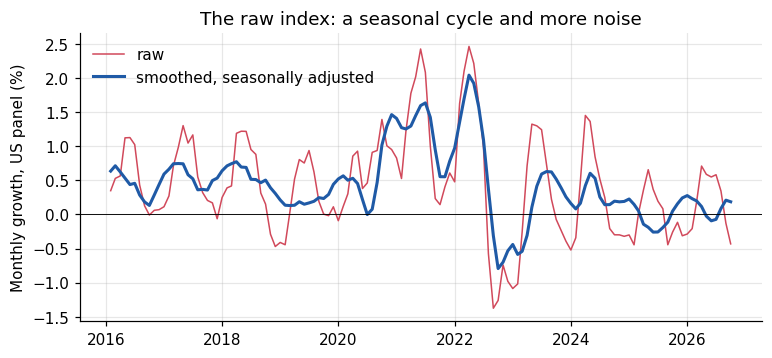

In [2]:
g_s, g_r = 100 * L_s["US"].diff(), 100 * L_r["US"].diff()
by_month = g_r.groupby(g_r.index.month).mean() - g_r.mean()
noise = {"monthly growth sd, smoothed (pp)": float(g_s.std()), "monthly growth sd, raw (pp)": float(g_r.std()),
         "seasonal swing, raw (pp, highest minus lowest month)": float(by_month.max() - by_month.min())}
write_metrics("06_raw_vs_smoothed", noise)
fig, ax = plt.subplots(figsize=(8, 3.4))
recent = g_s.index >= "2016-01-31"
ax.plot(g_r.index[recent], g_r[recent], color=COLORS["zillow"], lw=1, label="raw")
ax.plot(g_s.index[recent], g_s[recent], color=COLORS["ours"], lw=2, label="smoothed, seasonally adjusted")
ax.axhline(0, color="k", lw=0.6)
ax.set_ylabel("Monthly growth, US panel (%)")
ax.set_title("The raw index: a seasonal cycle and more noise")
ax.legend(frameon=False)
save(fig, "06_raw_vs_smoothed")
{k: round(v, 2) for k, v in noise.items()}

## 2. Accuracy on the raw index

RMSE of growth (pp) over the same 47 quarterly forecast dates, for the chosen forecast (refitted on
the raw index) and the three simple rules. The bar to beat at each level and horizon is now the best
of no change, momentum and seasonal naive.

In [3]:
order = ["combo+bottom_up", "naive", "momentum", "seasonal_naive"]
tab_r = ft.rmse_table(res_r[res_r["method"].isin(order)]).unstack("method")[order].reindex(LEVELS, level=0)
rules = ["naive", "momentum", "seasonal_naive"]
tab_r["best simple rule"] = tab_r[rules].idxmin(axis=1)
tab_r["skill vs best rule"] = 1 - tab_r["combo+bottom_up"] / tab_r[rules].min(axis=1)
write_metrics("06_raw_scores", tab_r.reset_index())
tab_r.round(3)

method       combo+bottom_up  naive  momentum  seasonal_naive  \
level    h                                                      
National 1             0.365  0.842     0.700           0.745   
         3             1.522  2.444     1.978           1.964   
         6             2.795  4.277     3.372           3.401   
         12            4.735  6.953     5.314           5.314   
State    1             0.460  0.947     0.794           0.805   
         3             1.795  2.673     2.206           2.069   
         6             3.184  4.604     3.667           3.545   
         12            5.091  7.384     5.611           5.611   
Metro    1             0.627  1.066     0.928           0.952   
         3             2.139  2.911     2.481           2.368   
         6             3.646  4.935     4.049           3.900   
         12            5.526  7.823     6.053           6.053   
County   1             0.681  1.104     0.974           1.014   
         3             2.244  2.973     2.581           2.519   
         6             3.790  5.005     4.196           4.088   
         12            5.680  7.882     6.282           6.282   

method      best simple rule  skill vs best rule  
level    h                                        
National 1          momentum               0.478  
         3    seasonal_naive               0.225  
         6          momentum               0.171  
         12         momentum               0.109  
State    1          momentum               0.421  
         3    seasonal_naive               0.133  
         6    seasonal_naive               0.102  
         12         momentum               0.093  
Metro    1          momentum               0.324  
         3    seasonal_naive               0.096  
         6    seasonal_naive               0.065  
         12         momentum               0.087  
County   1          momentum               0.301  
         3    seasonal_naive               0.109  
         6    seasonal_naive               0.073  
         12         momentum               0.096

### How sure? Date by date, against the best simple rule

As in notebook 05: each forecast date's mean squared error, a Diebold-Mariano test with the overlap
between dates allowed for, and a block-bootstrap interval for the skill. The rule compared against
is the best simple rule over all 47 dates at that level and horizon.

In [4]:
rows = []
for variant, res, tab in [("raw", res_r, tab_r)]:
    for period, sub in [("all 47 dates", res), ("test, 2023-25", res[res["period"] == "test"])]:
        for lv in LEVELS:
            for h in HORIZONS:
                rule = tab.loc[(lv, h), "best simple rule"]
                a = bt.per_date_mse(sub, "combo+bottom_up", lv, h)
                b = bt.per_date_mse(sub, rule, lv, h)
                lag = bt.overlap_lag(h)
                _, p = bt.dm_test(a, b, lag)
                lo, hi = bt.block_bootstrap_skill(a, b, block=max(lag + 1, 2))
                rows.append({"variant": variant, "period": period, "level": lv, "h": h, "rule": rule,
                             "skill": 1 - np.sqrt(a.mean() / b.mean()), "skill_lo95": lo, "skill_hi95": hi,
                             "dm_p": p})
sig_r = pd.DataFrame(rows)
write_metrics("06_raw_significance", sig_r)
sig_r[sig_r["level"].isin(["National", "Metro"])].set_index(["period", "level", "h"])[
    ["rule", "skill", "skill_lo95", "skill_hi95", "dm_p"]].round(3)

rule  skill  skill_lo95  skill_hi95  \
period        level    h                                                   
all 47 dates  National 1         momentum  0.478       0.322       0.584   
                       3   seasonal_naive  0.225       0.011       0.352   
                       6         momentum  0.171      -0.066       0.330   
                       12        momentum  0.109      -0.246       0.344   
              Metro    1         momentum  0.324       0.254       0.389   
                       3   seasonal_naive  0.096      -0.051       0.211   
                       6   seasonal_naive  0.065      -0.084       0.192   
                       12        momentum  0.087      -0.104       0.278   
test, 2023-25 National 1         momentum  0.408      -0.027       0.675   
                       3   seasonal_naive  0.223      -0.290       0.438   
                       6         momentum -0.204      -0.694       0.168   
                       12        momentum -0.150      -0.845       0.405   
              Metro    1         momentum  0.295       0.149       0.441   
                       3   seasonal_naive  0.052      -0.232       0.253   
                       6   seasonal_naive -0.084      -0.287       0.206   
                       12        momentum -0.052      -0.376       0.253   

                            dm_p  
period        level    h          
all 47 dates  National 1   0.009  
                       3   0.053  
                       6   0.310  
                       12  0.576  
              Metro    1   0.000  
                       3   0.158  
                       6   0.450  
                       12  0.504  
test, 2023-25 National 1   0.282  
                       3   0.323  
                       6   0.296  
                       12  0.751  
              Metro    1   0.083  
                       3   0.681  
                       6   0.567  
                       12  0.822

## 3. Smoothed against raw, side by side

Metro RMSE by horizon: the chosen forecast and the best simple rule, on each version of the index.

,smoothed: chosen,smoothed: best rule,raw: chosen,raw: best rule,smoothed skill,raw skill
h,,,,,,
1,0.217,0.540,0.627,0.928,0.599,0.324
3,1.080,1.650,2.139,2.368,0.345,0.096
6,2.473,3.122,3.646,3.900,0.208,0.065
12,5.059,5.895,5.526,6.053,0.142,0.087


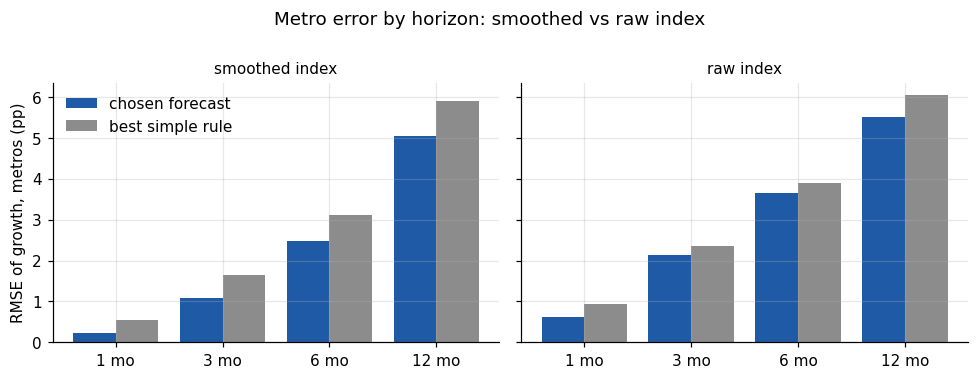

In [5]:
tab_s = ft.rmse_table(res_s[res_s["method"].isin(order)]).unstack("method")[order].reindex(LEVELS, level=0)
side = pd.DataFrame({
    "smoothed: chosen": tab_s.loc["Metro", "combo+bottom_up"],
    "smoothed: best rule": tab_s.loc["Metro", rules].min(axis=1),
    "raw: chosen": tab_r.loc["Metro", "combo+bottom_up"],
    "raw: best rule": tab_r.loc["Metro", rules].min(axis=1),
})
side["smoothed skill"] = 1 - side["smoothed: chosen"] / side["smoothed: best rule"]
side["raw skill"] = 1 - side["raw: chosen"] / side["raw: best rule"]
write_metrics("06_side_by_side_metro", side.reset_index())
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, v in zip(axes, ["smoothed", "raw"]):
    x = np.arange(len(side))
    ax.bar(x - 0.2, side[f"{v}: chosen"], 0.4, color=COLORS["ours"], label="chosen forecast")
    ax.bar(x + 0.2, side[f"{v}: best rule"], 0.4, color=COLORS["grey"], label="best simple rule")
    ax.set_xticks(x, [f"{h} mo" for h in side.index])
    ax.set_title(f"{v} index", fontsize=10)
axes[0].set_ylabel("RMSE of growth, metros (pp)")
axes[0].legend(frameon=False)
fig.suptitle("Metro error by horizon: smoothed vs raw index", y=1.0)
fig.tight_layout()
save(fig, "06_side_by_side")
side.round(3)

**Reading it.** On the raw index every method is worse, because month-to-month noise cannot be
forecast. The chosen forecast keeps a clear lead one month out: it is refitted on the raw series, so
its AR terms pick up the noise's quick reversal, which the simple rules cannot. From three months on,
a seasonal rule is nearly as good, and the remaining gap is within chance. For a lender that cares
about actual prices rather than Zillow's smoothed index, the honest claim is a better *next month*,
not a better quarter or year.

## 4. Summary

The cell below states the result in words from the recorded numbers.

In [6]:
m = sig_r[(sig_r["period"] == "all 47 dates") & (sig_r["level"] == "Metro")].set_index("h")
for h in HORIZONS:
    r = m.loc[h]
    verdict = ("better" if r["skill_lo95"] > 0 else "worse" if r["skill_hi95"] < 0 else "not distinguishable from")
    print(f"Metro, {h:>2} month(s): chosen forecast {r['skill']:+.0%} vs {r['rule']} "
          f"(95% interval {r['skill_lo95']:+.0%} to {r['skill_hi95']:+.0%}, p = {r['dm_p']:.3f}) -> {verdict} the best rule")

Metro,  1 month(s): chosen forecast +32% vs momentum (95% interval +25% to +39%, p = 0.000) -> better the best rule
Metro,  3 month(s): chosen forecast +10% vs seasonal_naive (95% interval -5% to +21%, p = 0.158) -> not distinguishable from the best rule
Metro,  6 month(s): chosen forecast +7% vs seasonal_naive (95% interval -8% to +19%, p = 0.450) -> not distinguishable from the best rule
Metro, 12 month(s): chosen forecast +9% vs momentum (95% interval -10% to +28%, p = 0.504) -> not distinguishable from the best rule
